## Solution for Assignment 01 Question 1 part c

In [5]:
# Solution for Assignment 01 Q1 part c

# Import and random seed setup
import torch

TORCH_SEED = 0

torch.random.manual_seed(TORCH_SEED)
print(f'Torch random seed set to {TORCH_SEED}')

# Constant definitions
d = 10       # dimensionality of the data & the model
N = 100      # number of data points
sigma = 0.01 # standard deviation of the distribution generating weights and data
lr = 25      # step size (learning rate) of the SGD
T = 2000     # Number of SGD iterations

# Init weights and dataset
w_star = sigma * torch.randn((d, 1)) # Optimal weights are randomly initialized from N(0, sigma)

# torch.normal(
#     mean=torch.zeros((d, 1)),
#     std=torch.tensor(sigma)
# ) # alternative notation

X = sigma * torch.randn((N, d))

y = X @ w_star # The true targets are calculated as w.T @ X[i] for every X[i]
# In torch notation:  X_{N x d} @ w_star_{d x 1} = y_{N x 1}

print(f'w shape: {tuple(w_star.size())}\t X shape: {tuple(X.shape)}\t y shape: {tuple(y.shape)}')

Torch random seed set to 0
w shape: (10, 1)	 X shape: (100, 10)	 y shape: (100, 1)


In [6]:
# SGD training

# Variables
w_t = torch.zeros((d, 1)) # w_t, init to all 0
Loss = []

# Run SGD
for t in range(T):
    # Calculate the loss as sum_i(y[i] - w_t.T @ X[i])
    Loss.append(torch.sum((y - X @ w_t) ** 2, axis=0))
    # Calculate the gradient_loss as sum_i( (w_t.T @ x[i]) * x[i] - y[i] * x[i] ) / N
    grad_L = torch.sum((X @ w_t) * X - y * X, axis=0).unsqueeze(1) / N
    # w_{t+1} = w_t - lr * gradient_loss
    w_t -= lr * grad_L
# Add the final calculated loss
Loss.append(torch.sum((y - X @ w_t) ** 2, axis=0))


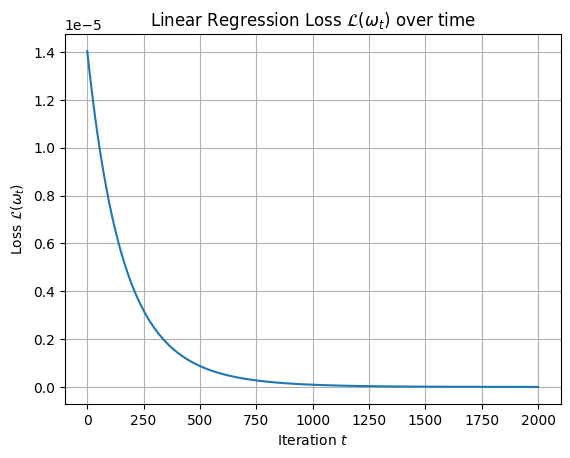

Final loss: tensor([2.3976e-09])


In [7]:
# Plot the loss over iterations
import matplotlib.pyplot as plt
plt.plot(Loss)
plt.xlabel(r'Iteration $t$')
plt.ylabel(r'Loss $\mathcal{L}(\omega_t)$')
plt.title(r'Linear Regression Loss $\mathcal{L}(\omega_t)$ over time')
plt.grid()
plt.show()

print(f'Final loss: {Loss[-1]}')

Final learning rate used: $\eta = 25$

## Solution for Assignment 01 part d

Torch random seed set to 0
w shape: (200, 1)	 X shape: (100, 200)	 y shape: (100, 1)


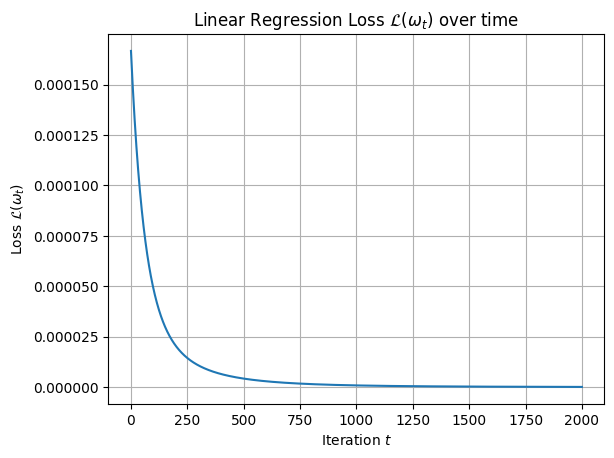

Final loss: tensor([1.3916e-07])


In [8]:
# Solution for Assignment 01 part c

# Imports and random seed setup
import torch

TORCH_SEED = 0

torch.random.manual_seed(TORCH_SEED)
print(f'Torch random seed set to {TORCH_SEED}')

# Constant definitions
d = 200      # dimensionality of the data & the model
N = 100      # number of data points
sigma = 0.01 # standard deviation of the distribution generating weights and data
lr = 25      # step size (learning rate) of the SGD
T = 2000     # Number of SGD iterations

# Init weights and dataset
w_star = sigma * torch.randn((d, 1)) # Optimal weights are randomly initialized from N(0, sigma)

# torch.normal(
#     mean=torch.zeros((d, 1)),
#     std=torch.tensor(sigma)
# ) # alternative notation

X = sigma * torch.randn((N, d))

y = X @ w_star # The true targets are calculated as w.T @ X[i] for every X[i]
# In torch notation:  X_{N x d} @ w_star_{d x 1} = y_{N x 1}

print(f'w shape: {tuple(w_star.size())}\t X shape: {tuple(X.shape)}\t y shape: {tuple(y.shape)}')

# SGD training

# Variables
w_t = torch.zeros((d, 1))  # w_t, init to all 0
Loss = []

# Run SGD
for t in range(T):
    # Calculate the loss as sum_i(y[i] - w_t.T @ X[i])
    Loss.append(torch.sum((y - X @ w_t) ** 2, axis=0))
    # Calculate the gradient_loss as sum_i( (w_t.T @ x[i]) * x[i] - y[i] * x[i] ) / N
    grad_L = torch.sum((X @ w_t) * X - y * X, axis=0).unsqueeze(1) / N
    # w_{t+1} = w_t - lr * gradient_loss
    w_t -= lr * grad_L
    # Update w_t = w_{t+1} for the next t
    w_current = w_t.clone()
# Add the final calculated loss
Loss.append(torch.sum((y - X @ w_t) ** 2, axis=0))

# Plot the loss over iterations
import matplotlib.pyplot as plt
plt.plot(Loss)
plt.xlabel(r'Iteration $t$')
plt.ylabel(r'Loss $\mathcal{L}(\omega_t)$')
plt.title(r'Linear Regression Loss $\mathcal{L}(\omega_t)$ over time')
plt.grid()
plt.show()

print(f'Final loss: {Loss[-1]}')

Final learning rate used: $\eta = 25$

Findings: 